# PRCP-1003 · Customer Transaction Prediction (Banking)

**Goal.** Identify which bank customers will make a transaction in the future, irrespective of the amount.
**Data.** 200,000 customers, `ID_code`, `target` (0 = no transaction, 1 = transaction) and 200 anonymised numeric features (`var_0` … `var_199`).

**How this notebook maps to the project brief**

| Brief requirement | Where |
|---|---|
| Task 1 – data analysis report | Part 2 |
| Task 2 – predictive model | Parts 3 – 8, 10 |
| Class balancing of the training data | Part 4b |
| Model Comparison Report | Parts 4, 4b, 5 and 11 |
| Report on Challenges | Part 12 |
| Conclusion linked to the problem statement | Part 13 |

**Evaluation approach (decided up-front).**
- Ranking quality is measured with **ROC-AUC** and **Average Precision (PR-AUC)** because only about 10% of customers transact, so accuracy is misleading.
- The data is split into three parts with strict roles: a **fit set** (model comparison and tuning, using cross-validation), a **validation set** (decision threshold, calibration, business value) and a **test set** that is used **once**, at the end.
- The **training data is balanced** (several strategies are compared in Part 4b), but only inside the training folds and the fit set. The validation and test sets keep the real ~10% rate, so the reported results reflect real use.
- Accuracy-style numbers (precision, recall) depend on a decision threshold, so the threshold is chosen from an explicit **cost / benefit assumption** rather than by maximising F1.
- No model is saved to disk. The trained model lives in the notebook and predictions are produced directly (Part 10).

## Part 1 · Setup and data loading

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, classification_report, roc_curve,
                             precision_recall_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)

# Optional libraries: used only if installed.
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
print(f"XGBoost available: {HAS_XGB} | LightGBM available: {HAS_LGBM}")

XGBoost available: True | LightGBM available: True


In [2]:
# ---- Run settings --------------------------------------------------------
RANDOM_STATE = 42
QUICK_RUN = False      # True = small, fast smoke test. Keep False for the final submission.
DATA_FILE = None       # e.g. "Data/train.csv" if the file is not found automatically

N_JOBS = -1
N_SPLITS_CV = 5                                   # folds for the model comparison
N_ITER_SEARCH = 3 if QUICK_RUN else 8             # random-search candidates (raise for a wider search)
N_BOOTSTRAP = 100 if QUICK_RUN else 500           # resamples for confidence intervals


def find_data_file(names, explicit=None, required=True):
    r"""C:\Users\kanap\Downloads\PRCP-1003-CustTransPred\Data\train(1).csv"""
    if explicit is not None:
        path = Path(explicit)
        if path.exists():
            return path
        raise FileNotFoundError(f"DATA_FILE not found: {path.resolve()}")
    for folder in [Path.cwd(), Path.cwd() / "Data", Path.cwd() / "data"]:
        for name in names:
            if (folder / name).exists():
                return folder / name
    for name in names:
        hits = sorted(Path.cwd().rglob(name))
        if hits:
            return hits[0]
    if required:
        raise FileNotFoundError(
            f"Could not find any of {names} under {Path.cwd()}. "
            "Put the CSV next to this notebook or set DATA_FILE above.")
    return None


data_path = find_data_file(["train.csv", "train(1).csv"], DATA_FILE)
print("Loading:", data_path.resolve())
df = pd.read_csv(data_path)

if QUICK_RUN:
    df = df.sample(n=min(30_000, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)
    print("QUICK_RUN is ON: using a 30,000-row sample. Results are for testing the code only.")

assert {"ID_code", "target"}.issubset(df.columns), "Expected ID_code and target columns"
feature_cols = [c for c in df.columns if c not in ("ID_code", "target")]
print(f"Rows: {len(df):,} | Features: {len(feature_cols)}")

Loading: C:\Users\kanap\Downloads\PRCP-1003-CustTransPred\Data\train(1).csv
Rows: 200,000 | Features: 200


## Part 2 · Data analysis report (Task 1)

In [3]:
# 2.1 First look
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print(df.dtypes.value_counts().to_string())
display(df.head())

# The 200 features are summarised together instead of printing a 200-row table
per_feature = df[feature_cols].agg(["mean", "std", "min", "max"]).T
print("\nRange of the per-feature statistics across all 200 features:")
display(per_feature.describe().loc[["min", "50%", "max"]].round(2))

Rows: 200,000 | Columns: 202
float64    200
str          1
int64        1


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,...,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,5.7470,2.9252,3.1821,14.0137,...,5.8764,11.8411,-19.7159,17.5743,0.5857,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,8.0851,-0.4032,8.0585,14.0239,...,-4.8622,7.6543,-15.9319,13.3175,-0.3566,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,-4.9193,5.9525,-0.3249,-11.2648,14.1929,...,-5.3000,5.3745,-6.2660,10.1934,-0.8417,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,-5.8609,8.2450,2.3061,2.8102,13.8463,...,-0.0498,7.9336,-12.8279,12.4124,1.8489,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,6.2654,7.6784,-9.4458,-12.1419,13.8481,...,-7.8931,6.4209,5.9270,16.0201,-0.2829,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104



Range of the per-feature statistics across all 200 features:


,mean,std,min,max
min,-16.55,0.01,-90.25,1.57
50%,6.58,3.94,-5.47,18.46
max,24.52,21.40,13.73,74.03


In [4]:
# 2.2 Data quality checks
quality = pd.DataFrame({
    "Check": ["Missing values", "Duplicate rows (on the 200 features)", "Duplicate ID_code values",
              "Infinite values", "Constant features", "Non-numeric features"],
    "Result": [
        int(df.isna().sum().sum()),
        int(df.duplicated(subset=feature_cols).sum()),
        int(df["ID_code"].duplicated().sum()),
        int(np.isinf(df[feature_cols]).sum().sum()),
        int((df[feature_cols].nunique() <= 1).sum()),
        int((~df[feature_cols].dtypes.apply(pd.api.types.is_numeric_dtype)).sum()),
    ],
})
display(quality)

,Check,Result
0,Missing values,0
1,Duplicate rows (on the 200 features),0
2,Duplicate ID_code values,0
3,Infinite values,0
4,Constant features,0
5,Non-numeric features,0


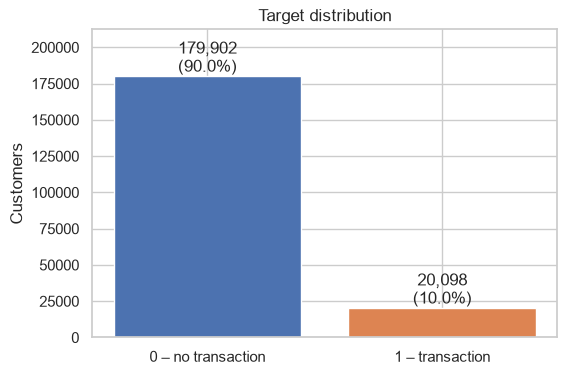

Class imbalance: about 9.0 non-transacting customers per transacting customer.


In [5]:
# 2.3 Target distribution
counts = df["target"].value_counts().sort_index()
pct = counts / counts.sum() * 100
imbalance_ratio = counts[0] / counts[1]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["0 – no transaction", "1 – transaction"], counts.values,
              color=sns.color_palette()[:2])
for bar, c, p in zip(bars, counts.values, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, c, f"{c:,}\n({p:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel("Customers")
ax.set_title("Target distribution")
plt.show()
print(f"Class imbalance: about {imbalance_ratio:.1f} non-transacting customers per transacting customer.")

In [6]:
# 2.4 Distributions and outliers (IQR rule: outside Q1 - 1.5*IQR or Q3 + 1.5*IQR)
X_all = df[feature_cols]
q1, q3 = X_all.quantile(0.25), X_all.quantile(0.75)
iqr = q3 - q1
outlier_mask = X_all.lt(q1 - 1.5 * iqr, axis=1) | X_all.gt(q3 + 1.5 * iqr, axis=1)

feat_summary = pd.DataFrame({
    "skew": X_all.skew(),
    "excess_kurtosis": X_all.kurt(),
    "outlier_%": outlier_mask.mean() * 100,
    "n_unique": X_all.nunique(),
})
print("Spread of these statistics across the 200 features:")
display(feat_summary.describe().loc[["min", "50%", "max"]].round(3))
print("Features with the highest share of outliers:")
display(feat_summary.nlargest(5, "outlier_%").round(3))

# Do customers with many outlying values behave differently? (group sizes shown)
row_outliers = outlier_mask.sum(axis=1)
bucket = pd.cut(row_outliers, [-1, 0, 2, 5, 10, np.inf], labels=["0", "1-2", "3-5", "6-10", ">10"])
outlier_rows = (pd.DataFrame({"bucket": bucket, "target": df["target"]})
                .groupby("bucket", observed=True)["target"]
                .agg(customers="size", transaction_rate_pct=lambda s: s.mean() * 100)
                .round(2))
outlier_rows.index.name = "outlying features per customer"
display(outlier_rows)

Spread of these statistics across the 200 features:


,skew,excess_kurtosis,outlier_%,n_unique
min,-0.340,-0.812,0.000,451.0
50%,0.017,-0.505,0.022,108872.5
max,0.267,-0.014,0.754,169968.0


Features with the highest share of outliers:


,skew,excess_kurtosis,outlier_%,n_unique
var_179,0.243,-0.014,0.754,90090
var_44,-0.340,-0.096,0.604,127702
var_93,-0.238,-0.152,0.444,26708
var_146,-0.125,-0.168,0.402,84314
var_192,0.084,-0.240,0.366,59065


,customers,transaction_rate_pct
outlying features per customer,,
0,175104,9.77
1-2,24814,12.01
3-5,82,14.63


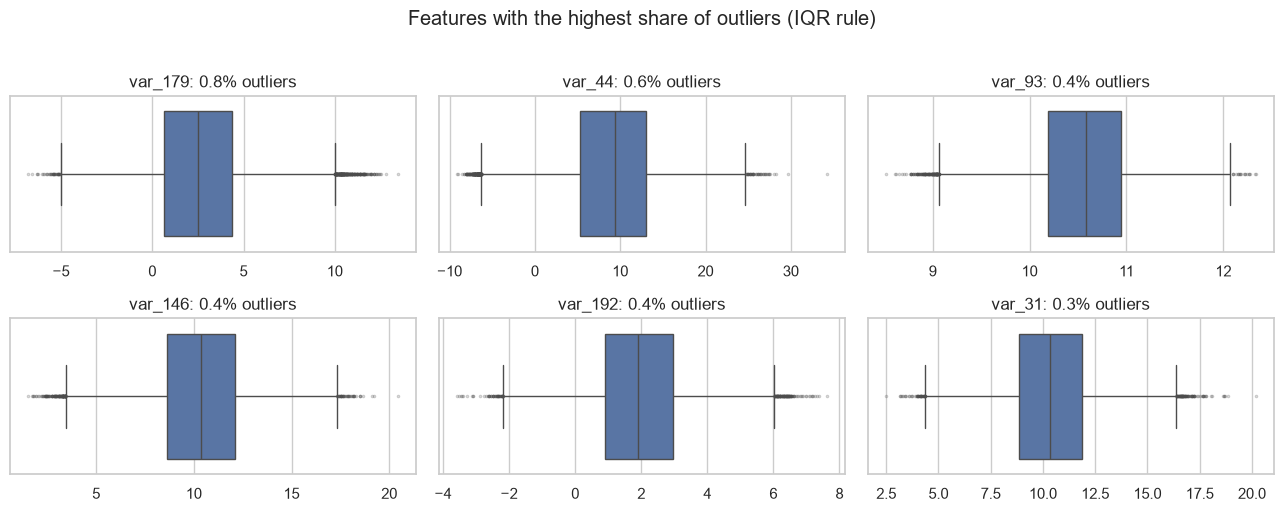

In [7]:
# 2.5 Box plots of the features with the most outliers
top_out = feat_summary["outlier_%"].nlargest(6).index
box_sample = df.sample(min(50_000, len(df)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for ax, col in zip(axes.ravel(), top_out):
    sns.boxplot(x=box_sample[col], ax=ax, fliersize=1.5, flierprops={"alpha": 0.3})
    ax.set_title(f"{col}: {feat_summary.loc[col, 'outlier_%']:.1f}% outliers")
    ax.set_xlabel("")
plt.suptitle("Features with the highest share of outliers (IQR rule)", y=1.02)
plt.tight_layout()
plt.show()

In [8]:
# 2.6 Low-variance features
low_var = pd.DataFrame({
    "variance": X_all.var(), "n_unique": X_all.nunique(), "min": X_all.min(), "max": X_all.max()
}).nsmallest(5, "variance")
display(low_var.round(4))

,variance,n_unique,min,max
var_68,0.0001,451,4.9938,5.0469
var_91,0.0233,7962,6.5218,7.4895
var_108,0.0293,8525,13.7290,14.7430
var_103,0.0342,9376,0.9793,2.1887
var_12,0.0361,9561,13.4346,14.6545


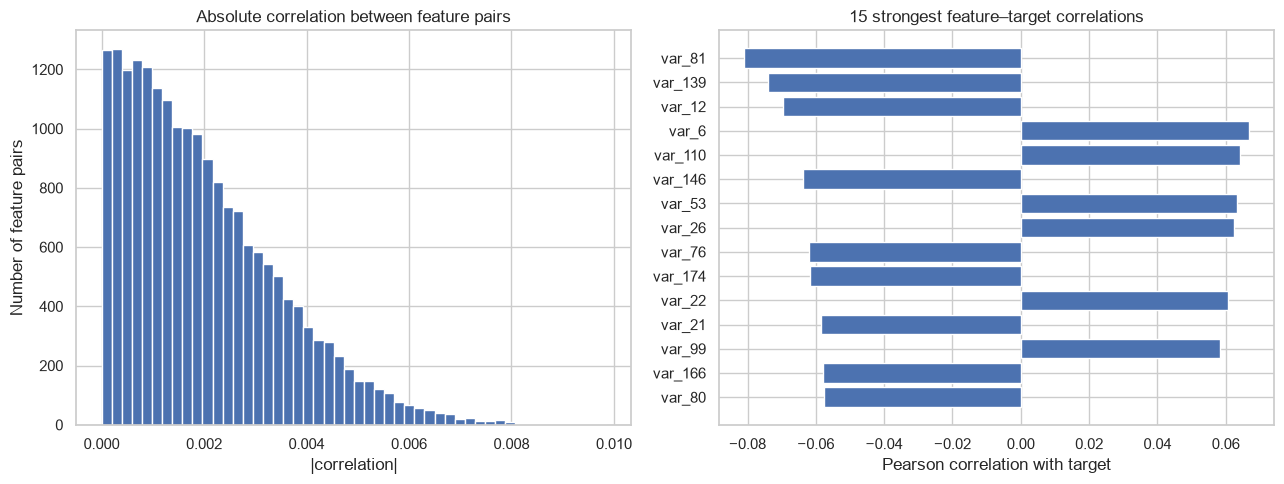

In [9]:
# 2.7 Correlation: feature vs feature, and feature vs target
corr_matrix = X_all.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr_matrix, np.nan)
max_pair_corr = float(np.nanmax(corr_matrix))
pair_values = corr_matrix[np.triu_indices_from(corr_matrix, k=1)]
target_corr = X_all.corrwith(df["target"])
top_target = target_corr.abs().nlargest(15).index[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(pair_values, bins=50)
axes[0].set_title("Absolute correlation between feature pairs")
axes[0].set_xlabel("|correlation|")
axes[0].set_ylabel("Number of feature pairs")
axes[1].barh(top_target, target_corr[top_target], color=sns.color_palette()[0])
axes[1].set_title("15 strongest feature–target correlations")
axes[1].set_xlabel("Pearson correlation with target")
plt.tight_layout()
plt.show()

In [10]:
# 2.8 Findings (generated from the results above so the numbers always match)
print("KEY FINDINGS")
print("-" * 60)
print(f"1. Data quality: {int(quality['Result'].sum())} problems found across all checks (missing, duplicates, infinite, constant, non-numeric).")
print(f"2. Target: {pct[1]:.1f}% of customers transact (imbalance ratio {imbalance_ratio:.1f}:1).")
print(f"3. Outliers: median feature has {feat_summary['outlier_%'].median():.2f}% outliers (max {feat_summary['outlier_%'].max():.2f}%).")
print(f"4. Feature redundancy: the strongest correlation between any two features is {max_pair_corr:.3f}.")
print(f"5. Individual signal: the strongest single-feature correlation with the target is {target_corr.abs().max():.3f}.")

KEY FINDINGS
------------------------------------------------------------
1. Data quality: 0 problems found across all checks (missing, duplicates, infinite, constant, non-numeric).
2. Target: 10.0% of customers transact (imbalance ratio 9.0:1).
3. Outliers: median feature has 0.02% outliers (max 0.75%).
4. Feature redundancy: the strongest correlation between any two features is 0.010.
5. Individual signal: the strongest single-feature correlation with the target is 0.081.


### Data-preparation decisions and the reasons

| Topic | Decision | Reason |
|---|---|---|
| `ID_code` | Dropped from the features | It is an identifier with no predictive meaning. It is kept aside only to label predictions. |
| Missing values | No imputation | None exist (see 2.2). If there had been, the **median** would be preferred over the mean for skewed features because it is not pulled by outliers. |
| Categorical / high-cardinality features | No encoding | All 200 features are numeric, so there is nothing to encode. |
| Outliers | Kept, not removed or clipped | The features are anonymised, so we cannot tell errors from genuine extremes. Tree-based models split on thresholds and are insensitive to extreme values. Logistic regression is scaled. The table in 2.4 shows whether customers with many outlying values behave differently from the rest. |
| Scaling | Only for logistic regression and PCA | Tree models are unaffected by feature scale. |
| Low-variance features | Kept | Low variance is not the same as low signal, and they cost almost nothing to keep. |
| Split | Stratified random split | Rows are independent customers and the file has no location, branch or time column, so a group- or time-based split is not possible. If the bank's real data had one, we would split on it to test generalisation to new locations or periods. |

## Part 3 · Train / validation / test split

Each part has one job. Keeping the roles separate is what prevents the same data from being used both to choose and to judge a model.

| Part | Used for |
|---|---|
| **Fit set** | Cross-validated model comparison and hyperparameter tuning |
| **Validation set** | Decision threshold, calibration check, business-value analysis |
| **Test set** | One final, unbiased evaluation. Nothing is chosen with it. |

In [11]:
X = df[feature_cols]
y = df["target"]
customer_ids = df["ID_code"]

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_dev, y_dev, test_size=0.15, stratify=y_dev, random_state=RANDOM_STATE)

# Safety checks: no customer appears in more than one part
assert set(X_fit.index).isdisjoint(X_val.index)
assert set(X_fit.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

y_fit_arr, y_val_arr, y_test_arr = y_fit.to_numpy(), y_val.to_numpy(), y_test.to_numpy()

split_table = pd.DataFrame({
    "Customers": [len(X_fit), len(X_val), len(X_test)],
    "Transacting (%)": [y_fit.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["Fit set", "Validation set", "Test set (locked)"]).round(2)
display(split_table)

,Customers,Transacting (%)
Fit set,136000,10.05
Validation set,24000,10.05
Test set (locked),40000,10.05


## Part 4 · Model comparison (5-fold cross-validation on the fit set)

**Fairness rules.** Every model sees exactly the same folds, none uses class weights, and models are ranked on threshold-free metrics (ROC-AUC, Average Precision). Threshold-dependent numbers such as precision and recall are reported at one common operating point: *contact the 10% of customers with the highest scores*, which is roughly the base rate.

**Runtime reasoning (Big O).** *n* = rows (about 109k per training fold), *p* = 200 features.

| Model | Rough training cost | Comment |
|---|---|---|
| Logistic regression | O(n·p) per iteration | Fast linear baseline |
| Gaussian Naive Bayes | O(n·p) | Very cheap. A useful check when features look independent |
| Random forest / Extra trees | O(T·√p·n·log n) for T trees | Cost grows with trees and depth, so depth and leaf size are limited here |
| Histogram gradient boosting, XGBoost, LightGBM | about O(iterations·n·p) | Linear in rows, which makes them practical at this size |
| KNN | Each prediction costs O(n·p) | Tens of thousands of queries against 128k rows is far too slow, so **excluded** |
| Kernel SVM | About O(n²) to O(n³) to train | Impractical at this size, so **excluded** |

Cross-validation multiplies the cost by the number of folds, which is why the tree ensembles are kept modest.

In [12]:
candidate_models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000))]),
    "Gaussian Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=12, min_samples_leaf=50, max_features="sqrt",
        n_jobs=N_JOBS, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100, max_depth=12, min_samples_leaf=50, max_features="sqrt",
        n_jobs=N_JOBS, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
if HAS_XGB:
    candidate_models["XGBoost"] = XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.5,
        tree_method="hist", eval_metric="auc", n_jobs=N_JOBS, random_state=RANDOM_STATE)
if HAS_LGBM:
    candidate_models["LightGBM"] = LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.5, n_jobs=N_JOBS, random_state=RANDOM_STATE, verbose=-1)


def top_fraction_metrics(y_true, scores, fraction=0.10):
    """Precision and recall when only the top `fraction` of scores is flagged."""
    k = max(1, int(len(y_true) * fraction))
    top = np.argsort(scores)[::-1][:k]
    hits = y_true[top].sum()
    return hits / k, hits / y_true.sum()


skf = StratifiedKFold(n_splits=N_SPLITS_CV, shuffle=True, random_state=RANDOM_STATE)
fold_rows = []
for name, model in candidate_models.items():
    started = time.perf_counter()
    for fold, (tr, te) in enumerate(skf.split(X_fit, y_fit_arr), start=1):
        m = clone(model)
        t0 = time.perf_counter()
        m.fit(X_fit.iloc[tr], y_fit_arr[tr])
        fit_seconds = time.perf_counter() - t0
        scores = m.predict_proba(X_fit.iloc[te])[:, 1]
        p10, r10 = top_fraction_metrics(y_fit_arr[te], scores)
        fold_rows.append({"Model": name, "Fold": fold,
                          "ROC-AUC": roc_auc_score(y_fit_arr[te], scores),
                          "Average precision": average_precision_score(y_fit_arr[te], scores),
                          "Precision@top10%": p10, "Recall@top10%": r10,
                          "Fit time (s)": fit_seconds})
    print(f"{name:<22} finished in {time.perf_counter() - started:6.0f} s")

cv_folds = pd.DataFrame(fold_rows)
cv_summary = (cv_folds.groupby("Model")
              .agg(auc_mean=("ROC-AUC", "mean"), auc_std=("ROC-AUC", "std"),
                   ap_mean=("Average precision", "mean"), ap_std=("Average precision", "std"),
                   precision_top10=("Precision@top10%", "mean"),
                   recall_top10=("Recall@top10%", "mean"),
                   fit_seconds=("Fit time (s)", "mean"))
              .sort_values("auc_mean", ascending=False))
display(cv_summary.round(4))

Logistic Regression    finished in      9 s
Gaussian Naive Bayes   finished in      5 s
Random Forest          finished in    187 s
Extra Trees            finished in     67 s
HistGradientBoosting   finished in     53 s
XGBoost                finished in     84 s
LightGBM               finished in     32 s


,auc_mean,auc_std,ap_mean,ap_std,precision_top10,recall_top10,fit_seconds
Model,,,,,,,
Gaussian Naive Bayes,0.8875,0.0034,0.5851,0.0078,0.5518,0.5492,0.7388
LightGBM,0.8755,0.0045,0.5527,0.0077,0.5272,0.5247,6.1466
XGBoost,0.8656,0.0041,0.5283,0.0095,0.5103,0.5078,16.5804
HistGradientBoosting,0.8616,0.0057,0.5110,0.0093,0.4988,0.4964,10.3014
Logistic Regression,0.8588,0.0044,0.5078,0.0067,0.4955,0.4931,1.5440
Extra Trees,0.8500,0.0045,0.4777,0.0144,0.4762,0.4740,13.0972
Random Forest,0.8154,0.0059,0.4141,0.0103,0.4235,0.4214,37.0484


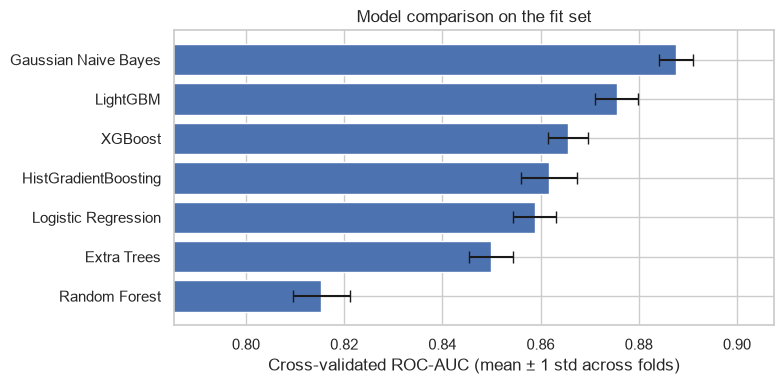

Best model by mean CV ROC-AUC: Gaussian Naive Bayes
Gaussian Naive Bayes minus LightGBM: mean +0.0121, better in 5 of 5 folds (same folds, so the comparison is paired).


In [13]:
# Visual comparison and a paired check between the top two models
fig, ax = plt.subplots(figsize=(8, 4))
order = cv_summary.index[::-1]
ax.barh(order, cv_summary.loc[order, "auc_mean"], xerr=cv_summary.loc[order, "auc_std"],
        capsize=4, color=sns.color_palette()[0])
ax.set_xlim(cv_summary["auc_mean"].min() - 0.03, cv_summary["auc_mean"].max() + 0.02)
ax.set_xlabel("Cross-validated ROC-AUC (mean ± 1 std across folds)")
ax.set_title("Model comparison on the fit set")
plt.tight_layout()
plt.show()

best_name, runner_up = cv_summary.index[0], cv_summary.index[1]
auc_best = cv_folds[cv_folds["Model"] == best_name].sort_values("Fold")["ROC-AUC"].to_numpy()
auc_second = cv_folds[cv_folds["Model"] == runner_up].sort_values("Fold")["ROC-AUC"].to_numpy()
diff = auc_best - auc_second
print(f"Best model by mean CV ROC-AUC: {best_name}")
print(f"{best_name} minus {runner_up}: mean {diff.mean():+.4f}, "
      f"better in {int((diff > 0).sum())} of {len(diff)} folds (same folds, so the comparison is paired).")

## Part 4b · Balancing the training data

The model should see transacting and non-transacting customers equally often during training. Balancing is done only on **training data**, and **inside each cross-validation fold**, for two reasons:
- If duplicated minority rows ended up in both the training and the scoring part of a fold, the model would be scored on rows it had already memorised and the results would look better than they are.
- The validation and test sets must keep the real ~10% rate, otherwise precision and business value would be overstated.

Plain over- and under-sampling each have a known weakness, so five balancing strategies are compared against the unbalanced reference:

| Strategy | What it does to the training rows | Weakness | How it is limited |
|---|---|---|---|
| **Class weights** | Nothing is added or removed. Minority errors count more | Little | Uses all the real data |
| **Random oversampling** | Minority rows are duplicated until classes are 1:1 | Repeated rows can be memorised (overfitting) | Done inside training folds only, and the tuning uses regularised settings |
| **Random undersampling** | Majority rows are dropped until classes are 1:1 | Throws away most of the majority information | Compared against the milder options below |
| **Hybrid** | Majority is reduced and minority duplicated, so both classes meet at the geometric mean of their sizes | Mild versions of both weaknesses | Far fewer duplicates and far fewer dropped rows than either extreme |
| **Undersampling ensemble** | Five models, each trained on all minority rows plus a *different* random majority subset, averaged | Five fits instead of one | Across the five models, much more of the majority data is used |

SMOTE (inventing new minority points by interpolation) is not used. It assumes that nearby customers are similar, which is doubtful for 200 anonymised, nearly uncorrelated features.

**Two consequences handled in the code.**
1. A model trained on balanced data over-estimates every probability. The wrapper below applies the standard prior correction, so probabilities match the real transaction rate again. The ranking (ROC-AUC) is not affected.
2. HistGradientBoosting's built-in early stopping holds back part of the *resampled* data, which would contain copies of training rows. Early stopping is therefore switched off for it and the number of boosting rounds is tuned instead.

In [14]:
from sklearn.base import BaseEstimator, ClassifierMixin


class BalancedClassifier(ClassifierMixin, BaseEstimator):
    """Wraps any classifier and balances the data it is fitted on.

    Resampling happens inside fit(), so it only ever touches the training rows it is given.
    strategy: none | class_weight | oversample | undersample | hybrid | bagging
    """

    def __init__(self, base=None, strategy="hybrid", n_bags=5, correct_prior=False, random_state=42):
        self.base = base
        self.strategy = strategy
        self.n_bags = n_bags
        self.correct_prior = correct_prior
        self.random_state = random_state

    def _index_sets(self, y):
        rng = np.random.default_rng(self.random_state)
        pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)

        def grow(rows, size):               # keep every original row, then add random repeats
            return np.concatenate([rows, rng.choice(rows, size - len(rows), replace=True)])

        def shrink(rows, size):             # random subset without repeats
            return rng.choice(rows, size, replace=False)

        s = self.strategy
        if s in ("none", "class_weight"):
            return [np.arange(len(y))]
        if s == "oversample":
            return [rng.permutation(np.concatenate([grow(pos, len(neg)), neg]))]
        if s == "undersample":
            return [rng.permutation(np.concatenate([pos, shrink(neg, len(pos))]))]
        if s == "hybrid":
            target = int(np.sqrt(len(pos) * len(neg)))
            return [rng.permutation(np.concatenate([grow(pos, target), shrink(neg, target)]))]
        if s == "bagging":
            return [rng.permutation(np.concatenate([pos, shrink(neg, len(pos))])) for _ in range(self.n_bags)]
        raise ValueError(f"Unknown strategy: {s}")

    def fit(self, X, y):
        y = np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        self.original_positive_rate_ = float(y.mean())
        self.models_, rows = [], []
        for idx in self._index_sets(y):
            model = clone(self.base)
            if self.strategy == "class_weight":
                params = model.get_params()
                if "class_weight" in params:
                    model.set_params(class_weight="balanced")
                elif "scale_pos_weight" in params:
                    model.set_params(scale_pos_weight=(y == 0).sum() / (y == 1).sum())
                else:
                    raise ValueError("This model has no class-weight option")
            X_part = X.iloc[idx] if hasattr(X, "iloc") else X[idx]
            model.fit(X_part, y[idx])
            self.models_.append(model)
            rows.append(len(idx))
        self.rows_per_model_ = int(np.mean(rows))
        # Share of positives the model effectively learned from
        self.effective_positive_rate_ = self.original_positive_rate_ if self.strategy == "none" else 0.5
        return self

    def predict_proba_raw(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.models_], axis=0)
        return np.column_stack([1 - p, p])

    def predict_proba(self, X):
        raw = self.predict_proba_raw(X)[:, 1]
        if not self.correct_prior or self.strategy == "none":
            return np.column_stack([1 - raw, raw])
        raw = np.clip(raw, 1e-9, 1 - 1e-9)
        odds_shift = ((self.original_positive_rate_ / (1 - self.original_positive_rate_)) /
                      (self.effective_positive_rate_ / (1 - self.effective_positive_rate_)))
        odds = raw / (1 - raw) * odds_shift
        p = odds / (1 + odds)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

In [15]:
# Which boosting family do we balance and tune? The best-ranked one that has a tuning space in Part 5.
tunable = [n for n in cv_summary.index if n in ("HistGradientBoosting", "XGBoost", "LightGBM")]
tune_name = tunable[0]

base_for_balancing = clone(candidate_models[tune_name])
if tune_name == "HistGradientBoosting":
    base_for_balancing.set_params(early_stopping=False, max_iter=200)   # see note above

strategies = {
    "No balancing (reference)": "none",
    "Class weights": "class_weight",
    "Random oversampling 1:1": "oversample",
    "Random undersampling 1:1": "undersample",
    "Hybrid (meet in the middle)": "hybrid",
    "Undersampling ensemble (5 bags)": "bagging",
}

balance_rows = []
for label, key in strategies.items():
    started = time.perf_counter()
    for fold, (tr, te) in enumerate(skf.split(X_fit, y_fit_arr), start=1):
        m = BalancedClassifier(base=base_for_balancing, strategy=key, random_state=RANDOM_STATE)
        m.fit(X_fit.iloc[tr], y_fit_arr[tr])                     # balancing happens inside the training fold only
        scores = m.predict_proba_raw(X_fit.iloc[te])[:, 1]       # the scoring fold keeps the real class mix
        p10, r10 = top_fraction_metrics(y_fit_arr[te], scores)
        balance_rows.append({"Strategy": label, "Fold": fold,
                             "ROC-AUC": roc_auc_score(y_fit_arr[te], scores),
                             "Average precision": average_precision_score(y_fit_arr[te], scores),
                             "Precision@top10%": p10, "Recall@top10%": r10,
                             "Rows per model": m.rows_per_model_})
    print(f"{label:<34} finished in {time.perf_counter() - started:5.0f} s")

balance_folds = pd.DataFrame(balance_rows)
balance_summary = (balance_folds.groupby("Strategy", sort=False)
                   .agg(auc_mean=("ROC-AUC", "mean"), auc_std=("ROC-AUC", "std"),
                        ap_mean=("Average precision", "mean"),
                        precision_top10=("Precision@top10%", "mean"),
                        recall_top10=("Recall@top10%", "mean"),
                        rows_per_model=("Rows per model", "mean")))
display(balance_summary.round(4))

No balancing (reference)           finished in    51 s
Class weights                      finished in    50 s
Random oversampling 1:1            finished in    88 s
Random undersampling 1:1           finished in    13 s
Hybrid (meet in the middle)        finished in    31 s
Undersampling ensemble (5 bags)    finished in   110 s


,auc_mean,auc_std,ap_mean,precision_top10,recall_top10,rows_per_model
Strategy,,,,,,
No balancing (reference),0.8755,0.0045,0.5527,0.5272,0.5247,108800.0
Class weights,0.8756,0.0044,0.5551,0.5270,0.5244,108800.0
Random oversampling 1:1,0.8743,0.0041,0.5504,0.5261,0.5236,195734.4
Random undersampling 1:1,0.8749,0.0036,0.5504,0.5259,0.5233,21865.6
Hybrid (meet in the middle),0.8741,0.0043,0.5520,0.5285,0.5260,65419.6
Undersampling ensemble (5 bags),0.8822,0.0040,0.5737,0.5419,0.5393,21865.6


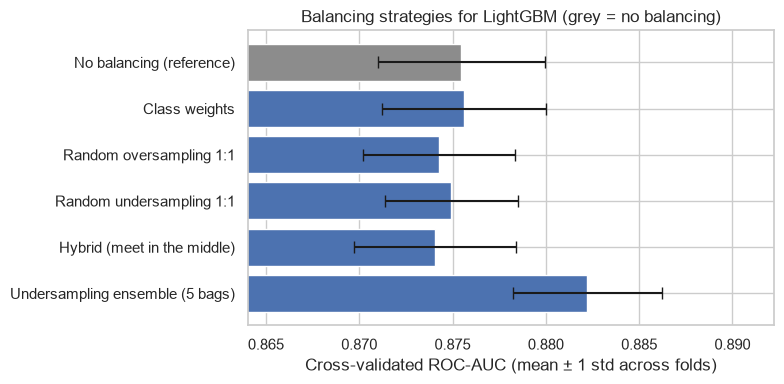

Selected balancing strategy: Undersampling ensemble (5 bags)
Compared with training on the original data: ROC-AUC +0.0068, Average precision +0.0210.
Balancing mainly changes the probability scale and the precision/recall trade-off; whether it improves ranking is shown by these two numbers, not assumed.
Note: the ensemble also averages five models, so part of its gain can come from averaging (less variance) rather than from balancing alone.


In [17]:
# Choose among the balanced strategies (the unbalanced row is only a reference)
reference_label = "No balancing (reference)"
candidates = balance_summary.drop(index=reference_label)
balance_label = candidates["auc_mean"].idxmax()
balance_strategy = strategies[balance_label]
delta_auc = candidates.loc[balance_label, "auc_mean"] - balance_summary.loc[reference_label, "auc_mean"]
delta_ap = candidates.loc[balance_label, "ap_mean"] - balance_summary.loc[reference_label, "ap_mean"]

fig, ax = plt.subplots(figsize=(8, 4))
order = balance_summary.index[::-1]
ax.barh(order, balance_summary.loc[order, "auc_mean"], xerr=balance_summary.loc[order, "auc_std"],
        capsize=4, color=[sns.color_palette()[7] if o == reference_label else sns.color_palette()[0] for o in order])
ax.set_xlim(balance_summary["auc_mean"].min() - 0.01, balance_summary["auc_mean"].max() + 0.01)
ax.set_xlabel("Cross-validated ROC-AUC (mean ± 1 std across folds)")
ax.set_title(f"Balancing strategies for {tune_name} (grey = no balancing)")
plt.tight_layout()
plt.show()

print(f"Selected balancing strategy: {balance_label}")
print(f"Compared with training on the original data: ROC-AUC {delta_auc:+.4f}, Average precision {delta_ap:+.4f}.")
print("Balancing mainly changes the probability scale and the precision/recall trade-off; "
      "whether it improves ranking is shown by these two numbers, not assumed.")
if balance_strategy == "bagging":
    print("Note: the ensemble also averages five models, so part of its gain can come from averaging "
          "(less variance) rather than from balancing alone.")

## Part 5 · Hyperparameter tuning (fit set only)

The best gradient-boosting model is tuned with a randomised search using 3-fold cross-validation on the **fit set only**. The model is wrapped with the balancing strategy chosen in Part 4b, so every training fold is balanced and every scoring fold keeps the real class mix. The search space deliberately includes strongly regularised settings (small trees, large leaves, high L2), which matters most when minority rows are duplicated. For HistGradientBoosting the number of rounds is tuned instead of using early stopping (see the note in Part 4b).

The search's own best score is slightly optimistic because it is the maximum over several candidates. The honest check is the untouched validation set in Part 6.

In [18]:
search_spaces = {
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE),
        {"learning_rate": [0.03, 0.05, 0.08, 0.1],
         "max_iter": [100, 150, 200],
         "max_leaf_nodes": [7, 15, 31, 63],
         "min_samples_leaf": [20, 50, 100, 200],
         "l2_regularization": [0.0, 1.0, 5.0, 10.0, 20.0]}),
}
if HAS_XGB:
    search_spaces["XGBoost"] = (
        XGBClassifier(tree_method="hist", eval_metric="auc", n_jobs=N_JOBS, random_state=RANDOM_STATE),
        {"n_estimators": [200, 400], "learning_rate": [0.03, 0.05, 0.1],
         "max_depth": [2, 3, 4, 6], "min_child_weight": [1, 5, 10],
         "subsample": [0.7, 0.9], "colsample_bytree": [0.3, 0.5, 0.8],
         "reg_lambda": [1, 5, 10]})
if HAS_LGBM:
    search_spaces["LightGBM"] = (
        LGBMClassifier(subsample_freq=1, n_jobs=N_JOBS, random_state=RANDOM_STATE, verbose=-1),
        {"n_estimators": [200, 400], "learning_rate": [0.03, 0.05, 0.1],
         "num_leaves": [7, 15, 31], "min_child_samples": [20, 50, 100],
         "subsample": [0.7, 0.9], "colsample_bytree": [0.3, 0.5, 0.8],
         "reg_lambda": [1, 5, 10]})

# tune_name was chosen in Part 4b (best-ranked model that has a search space)
if tune_name == best_name:
    selection_note = f"{tune_name} ranked first in cross-validation (ROC-AUC {cv_summary.loc[tune_name, 'auc_mean']:.4f})."
else:
    selection_note = (f"{best_name} ranked first in cross-validation (ROC-AUC {cv_summary.loc[best_name, 'auc_mean']:.4f}), "
                      f"but it has no boosting search space here, so {tune_name}, the best tunable model "
                      f"(ROC-AUC {cv_summary.loc[tune_name, 'auc_mean']:.4f}), was taken forward.")
print(selection_note)
print("Tuning:", tune_name)

base_estimator, param_grid = search_spaces[tune_name]
balanced_estimator = BalancedClassifier(base=base_estimator, strategy=balance_strategy,
                                        random_state=RANDOM_STATE)
param_grid = {f"base__{name}": values for name, values in param_grid.items()}
print("Balancing strategy:", balance_label)
search = RandomizedSearchCV(
    balanced_estimator, param_grid, n_iter=N_ITER_SEARCH, scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1, return_train_score=True, refit=True, verbose=1)

started = time.perf_counter()
search.fit(X_fit, y_fit)
print(f"Search finished in {(time.perf_counter() - started) / 60:.1f} minutes")

results = (pd.DataFrame(search.cv_results_)
           .sort_values("rank_test_score")
           [["rank_test_score", "mean_test_score", "std_test_score", "mean_train_score", "params"]]
           .head(5))
display(results.round(4))

final_model = search.best_estimator_      # already refitted (balanced) on the fit set only
final_model.set_params(correct_prior=True)  # predict_proba now returns probabilities on the real-world scale
default_cv_auc = cv_summary.loc[tune_name, "auc_mean"]
print(f"Best parameters: {search.best_params_}")
print(f"CV ROC-AUC: untuned model on original data {default_cv_auc:.4f} -> tuned balanced model {search.best_score_:.4f} "
      f"(difference {search.best_score_ - default_cv_auc:+.4f}; folds and settings differ, so treat as indicative)")

Gaussian Naive Bayes ranked first in cross-validation (ROC-AUC 0.8875), but it has no boosting search space here, so LightGBM, the best tunable model (ROC-AUC 0.8755), was taken forward.
Tuning: LightGBM
Balancing strategy: Undersampling ensemble (5 bags)
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Search finished in 9.7 minutes


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
3,1,0.8910,0.0022,0.9282,"{'base__subsample': 0.7, 'base__reg_lambda': 1..."
2,2,0.8902,0.0025,0.9689,"{'base__subsample': 0.7, 'base__reg_lambda': 5..."
0,3,0.8853,0.0023,0.9496,"{'base__subsample': 0.7, 'base__reg_lambda': 1..."
4,4,0.8837,0.0023,0.9445,"{'base__subsample': 0.7, 'base__reg_lambda': 1..."
5,5,0.8823,0.0023,0.9473,"{'base__subsample': 0.9, 'base__reg_lambda': 1..."


Best parameters: {'base__subsample': 0.7, 'base__reg_lambda': 1, 'base__num_leaves': 7, 'base__n_estimators': 400, 'base__min_child_samples': 50, 'base__learning_rate': 0.1, 'base__colsample_bytree': 0.3}
CV ROC-AUC: untuned model on original data 0.8755 -> tuned balanced model 0.8910 (difference +0.0156; folds and settings differ, so treat as indicative)


## Part 6 · Validation: overfitting and probability calibration

The validation set was not used for any choice so far, so it gives an honest read of the tuned model.

In [19]:
fit_scores = final_model.predict_proba(X_fit)[:, 1]
val_scores = final_model.predict_proba(X_val)[:, 1]

overfit = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_fit_arr, fit_scores), roc_auc_score(y_val_arr, val_scores)],
    "Average precision": [average_precision_score(y_fit_arr, fit_scores),
                          average_precision_score(y_val_arr, val_scores)],
}, index=["Fit set (seen in training)", "Validation set (unseen)"])
display(overfit.round(4))
gap = overfit.iloc[0, 0] - overfit.iloc[1, 0]
print(f"Train-minus-validation ROC-AUC gap: {gap:.4f}")
print("A large gap means the model memorises some training noise (more likely when minority rows are duplicated). "
      "What matters for use is the validation figure. Regularised settings are the main control applied here.")

,ROC-AUC,Average precision
Fit set (seen in training),0.9189,0.6624
Validation set (unseen),0.8958,0.5998


Train-minus-validation ROC-AUC gap: 0.0231
A large gap means the model memorises some training noise (more likely when minority rows are duplicated). What matters for use is the validation figure. Regularised settings are the main control applied here.


In [ ]:
# Are the predicted probabilities trustworthy as probabilities?
# Balanced training inflates raw probabilities; the prior correction brings them back to the real-world scale.
raw_val = final_model.predict_proba_raw(X_val)[:, 1]
brier_baseline = y_val_arr.mean() * (1 - y_val_arr.mean())      # always predicting the base rate

fig, ax = plt.subplots(figsize=(5.8, 5))
for label, probs in [("Raw (trained on balanced data)", raw_val), ("After prior correction (used below)", val_scores)]:
    frac_pos, mean_pred = calibration_curve(y_val_arr, probs, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=label)
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed transaction rate")
ax.set_title("Calibration on the validation set")
ax.legend()
plt.show()

brier = brier_score_loss(y_val_arr, val_scores)
print(f"Brier score: raw {brier_score_loss(y_val_arr, raw_val):.4f} | corrected {brier:.4f} "
      f"| base-rate-only reference {brier_baseline:.4f} (lower is better)")
print(f"ROC-AUC raw {roc_auc_score(y_val_arr, raw_val):.4f} vs corrected {roc_auc_score(y_val_arr, val_scores):.4f} "
      "(identical ranking, only the probability scale changes).")

## Part 7 · Decision threshold and business value

A probability only becomes a decision once we choose a threshold. Maximising F1 treats a missed customer and a wasted contact as equally bad, which is rarely true for a bank.

The data has no monetary values, so the values below are **illustrative assumptions to be replaced with the bank's real figures**:
- `VALUE_PER_TRANSACTOR`: benefit of reaching a customer who will go on to transact
- `COST_PER_CONTACT`: cost of contacting one customer (campaign, call, offer)

For every threshold, `net value = VALUE × (true transactors reached) − COST × (customers contacted)`. With a 5:1 value-to-cost ratio, contacting a customer pays off on average when their probability is above 1/5 = 0.20. The probabilities used here are the prior-corrected ones from Part 6, so the 1/5 rule of thumb holds. The threshold is chosen on the **validation set**.

In [20]:
VALUE_PER_TRANSACTOR = 5.0     # ASSUMPTION – replace with the bank's real figure
COST_PER_CONTACT = 1.0         # ASSUMPTION – replace with the bank's real figure


def threshold_table(y_true, scores, thresholds, value, cost):
    n, positives = len(y_true), int(y_true.sum())
    rows = []
    for t in thresholds:
        flagged_mask = scores >= t
        flagged = int(flagged_mask.sum())
        tp = int((flagged_mask & (y_true == 1)).sum())
        precision = tp / flagged if flagged else 0.0
        recall = tp / positives
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
        rows.append({"threshold": t, "flagged_%": 100 * flagged / n, "precision": precision,
                     "recall": recall, "f1": f1,
                     "net_value_per_1000": (value * tp - cost * flagged) / n * 1000})
    return pd.DataFrame(rows)


thresholds = np.round(np.arange(0.02, 0.80, 0.01), 2)
val_table = threshold_table(y_val_arr, val_scores, thresholds, VALUE_PER_TRANSACTOR, COST_PER_CONTACT)

THRESHOLD = float(val_table.loc[val_table["net_value_per_1000"].idxmax(), "threshold"])
f1_threshold = float(val_table.loc[val_table["f1"].idxmax(), "threshold"])
contact_all = (VALUE_PER_TRANSACTOR * y_val_arr.sum() - COST_PER_CONTACT * len(y_val_arr)) / len(y_val_arr) * 1000

display(val_table[val_table["threshold"].isin([0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60])].round(3))
print(f"Chosen threshold (maximum net value on validation): {THRESHOLD:.2f}")
print(f"For comparison, the F1-maximising threshold is {f1_threshold:.2f}")
print(f"Net value per 1,000 customers: model at {THRESHOLD:.2f} = "
      f"{val_table.loc[val_table['threshold'] == THRESHOLD, 'net_value_per_1000'].iloc[0]:,.0f} | "
      f"contact everyone = {contact_all:,.0f} | contact no-one = 0")

,threshold,flagged_%,precision,recall,f1,net_value_per_1000
3,0.05,46.233,0.204,0.940,0.336,10.167
8,0.10,25.388,0.324,0.818,0.464,157.167
13,0.15,16.042,0.437,0.697,0.537,190.000
18,0.20,10.921,0.535,0.582,0.558,183.083
23,0.25,7.942,0.620,0.490,0.547,166.625
28,0.30,5.871,0.700,0.409,0.517,146.917
38,0.40,3.412,0.823,0.279,0.417,106.292
48,0.50,1.992,0.885,0.175,0.293,68.208
58,0.60,1.129,0.915,0.103,0.185,40.375


Chosen threshold (maximum net value on validation): 0.16
For comparison, the F1-maximising threshold is 0.22
Net value per 1,000 customers: model at 0.16 = 190 | contact everyone = -498 | contact no-one = 0


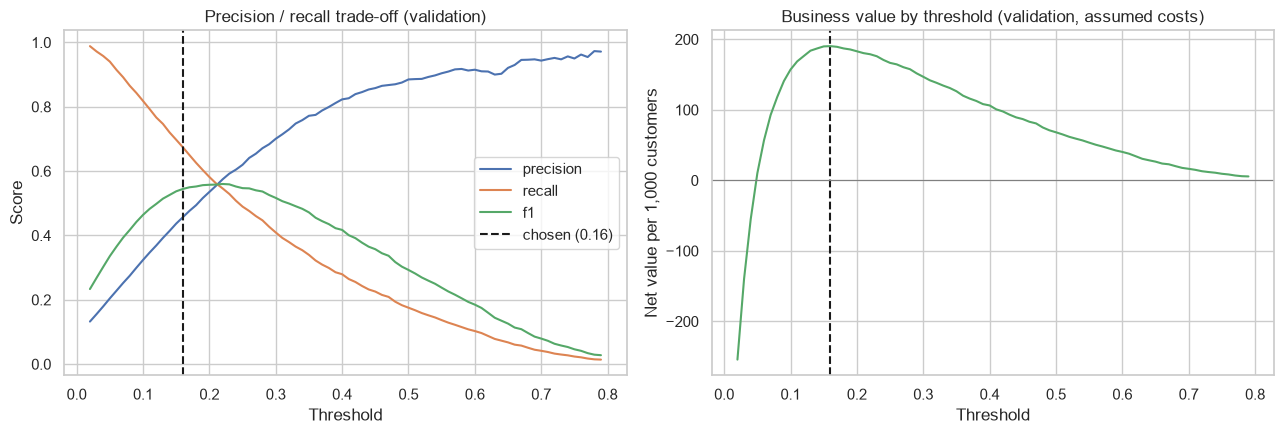

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for metric in ["precision", "recall", "f1"]:
    axes[0].plot(val_table["threshold"], val_table[metric], label=metric)
axes[0].axvline(THRESHOLD, color="k", linestyle="--", label=f"chosen ({THRESHOLD:.2f})")
axes[0].set_xlabel("Threshold"); axes[0].set_ylabel("Score")
axes[0].set_title("Precision / recall trade-off (validation)")
axes[0].legend()

axes[1].plot(val_table["threshold"], val_table["net_value_per_1000"], color=sns.color_palette()[2])
axes[1].axvline(THRESHOLD, color="k", linestyle="--")
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_xlabel("Threshold"); axes[1].set_ylabel("Net value per 1,000 customers")
axes[1].set_title("Business value by threshold (validation, assumed costs)")
plt.tight_layout()
plt.show()

,value : cost,best threshold,customers contacted (%),recall,precision,"net value per 1,000"
0,2 : 1,0.33,4.908,0.365,0.748,24.333
1,3 : 1,0.23,8.979,0.529,0.592,69.708
2,5 : 1,0.16,14.838,0.674,0.457,190.375
3,10 : 1,0.10,25.388,0.818,0.324,568.208
4,20 : 1,0.07,35.538,0.892,0.252,1437.125


,customers,transactors,response_rate_%,lift,cumulative_capture_%
decile,,,,,
1,2400,1346,56.08,5.58,55.80
2,2400,476,19.83,1.97,75.54
3,2400,239,9.96,0.99,85.45
4,2400,142,5.92,0.59,91.33
5,2400,84,3.50,0.35,94.82
6,2400,50,2.08,0.21,96.89
7,2400,33,1.38,0.14,98.26
8,2400,25,1.04,0.10,99.30
9,2400,14,0.58,0.06,99.88


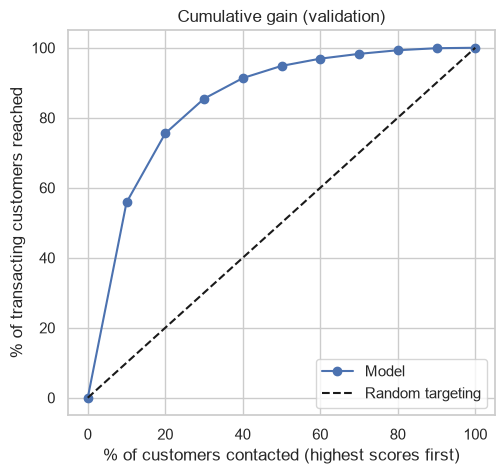

In [22]:
# How sensitive is the decision to the assumed value-to-cost ratio?
sens_rows = []
for ratio in [2, 3, 5, 10, 20]:
    tab = threshold_table(y_val_arr, val_scores, thresholds, float(ratio), 1.0)
    best = tab.loc[tab["net_value_per_1000"].idxmax()]
    sens_rows.append({"value : cost": f"{ratio} : 1", "best threshold": best["threshold"],
                      "customers contacted (%)": best["flagged_%"], "recall": best["recall"],
                      "precision": best["precision"], "net value per 1,000": best["net_value_per_1000"]})
display(pd.DataFrame(sens_rows).round(3))

# Lift / gain: how many transactors do we find if we call the top-scored customers first?
val_df = pd.DataFrame({"y": y_val_arr, "score": val_scores})
val_df["decile"] = pd.qcut(val_df["score"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = val_df.groupby("decile", observed=True).agg(customers=("y", "size"), transactors=("y", "sum"))
lift["response_rate_%"] = lift["transactors"] / lift["customers"] * 100
lift["lift"] = lift["response_rate_%"] / (y_val_arr.mean() * 100)
lift["cumulative_capture_%"] = lift["transactors"].cumsum() / lift["transactors"].sum() * 100
display(lift.round(2))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0] + list(range(10, 101, 10)), [0] + lift["cumulative_capture_%"].tolist(), marker="o", label="Model")
ax.plot([0, 100], [0, 100], "k--", label="Random targeting")
ax.set_xlabel("% of customers contacted (highest scores first)")
ax.set_ylabel("% of transacting customers reached")
ax.set_title("Cumulative gain (validation)")
ax.legend()
plt.show()

## Part 8 · Final evaluation on the locked test set (used once)

No choice below depends on the test set: the model came from the fit set and the threshold from the validation set. Uncertainty is shown with a 95% bootstrap confidence interval: the test customers are resampled with replacement many times and the metrics recomputed each time.

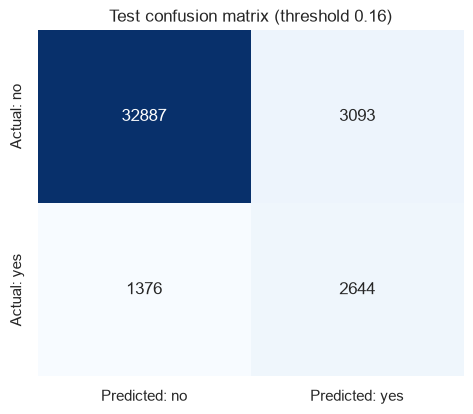

                precision    recall  f1-score   support

No transaction       0.96      0.91      0.94     35980
   Transaction       0.46      0.66      0.54      4020

      accuracy                           0.89     40000
     macro avg       0.71      0.79      0.74     40000
  weighted avg       0.91      0.89      0.90     40000



In [23]:
def evaluate_at_threshold(y_true, scores, threshold, value=VALUE_PER_TRANSACTOR, cost=COST_PER_CONTACT):
    pred = scores >= threshold
    tp = int((pred & (y_true == 1)).sum())
    fp = int((pred & (y_true == 0)).sum())
    fn = int((~pred & (y_true == 1)).sum())
    tn = int((~pred & (y_true == 0)).sum())
    flagged = tp + fp
    precision = tp / flagged if flagged else 0.0
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {"ROC-AUC": roc_auc_score(y_true, scores),
            "Average precision": average_precision_score(y_true, scores),
            "Accuracy": (tp + tn) / len(y_true),
            "Precision": precision, "Recall": recall, "F1": f1,
            "Customers contacted (%)": 100 * flagged / len(y_true),
            "Net value per 1,000 customers": (value * tp - cost * flagged) / len(y_true) * 1000}


test_scores = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_scores >= THRESHOLD).astype(int)
test_metrics = evaluate_at_threshold(y_test_arr, test_scores, THRESHOLD)

cm = confusion_matrix(y_test_arr, test_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted: no", "Predicted: yes"], yticklabels=["Actual: no", "Actual: yes"])
ax.set_title(f"Test confusion matrix (threshold {THRESHOLD:.2f})")
plt.show()
print(classification_report(y_test_arr, test_pred, target_names=["No transaction", "Transaction"]))

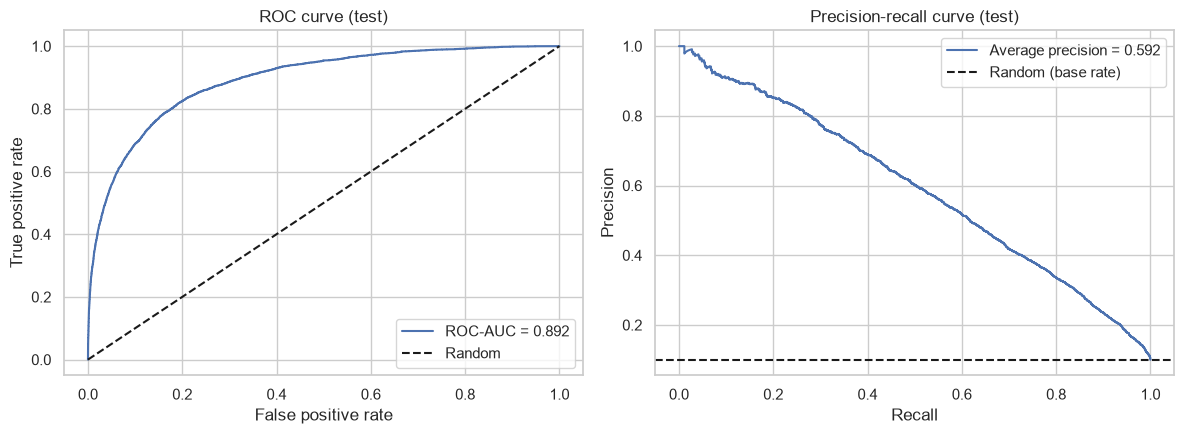

In [24]:
fpr, tpr, _ = roc_curve(y_test_arr, test_scores)
prec_curve, rec_curve, _ = precision_recall_curve(y_test_arr, test_scores)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {test_metrics['ROC-AUC']:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve (test)"); axes[0].legend()

axes[1].plot(rec_curve, prec_curve, label=f"Average precision = {test_metrics['Average precision']:.3f}")
axes[1].axhline(y_test_arr.mean(), color="k", linestyle="--", label="Random (base rate)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve (test)"); axes[1].legend()
plt.tight_layout()
plt.show()

In [26]:
# 95% bootstrap confidence intervals for the test metrics
rng = np.random.default_rng(RANDOM_STATE)
n_test = len(y_test_arr)
boot = []
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_test, n_test)
    boot.append(evaluate_at_threshold(y_test_arr[idx], test_scores[idx], THRESHOLD))
boot = pd.DataFrame(boot)

test_ci = pd.DataFrame({
    "Test value": pd.Series(test_metrics),
    "95% CI low": boot.quantile(0.025),
    "95% CI high": boot.quantile(0.975),
})
display(test_ci.round(4))
print(f"Based on {N_BOOTSTRAP} bootstrap resamples of {n_test:,} test customers.")

,Test value,95% CI low,95% CI high
ROC-AUC,0.8919,0.8866,0.8971
Average precision,0.5917,0.5772,0.6068
Accuracy,0.8883,0.8852,0.8912
Precision,0.4609,0.4485,0.4728
Recall,0.6577,0.6435,0.6731
F1,0.5420,0.5312,0.5538
Customers contacted (%),14.3425,14.0037,14.6838
"Net value per 1,000 customers",187.0750,177.1594,196.4513


Based on 500 bootstrap resamples of 40,000 test customers.


## Part 9 · Feature importance, feature selection and dimensionality reduction

Three questions: which features matter, can we drop features without losing accuracy, and would PCA help? Feature ranking for the selection experiment uses the **fit set only**, so the validation set stays an honest judge.

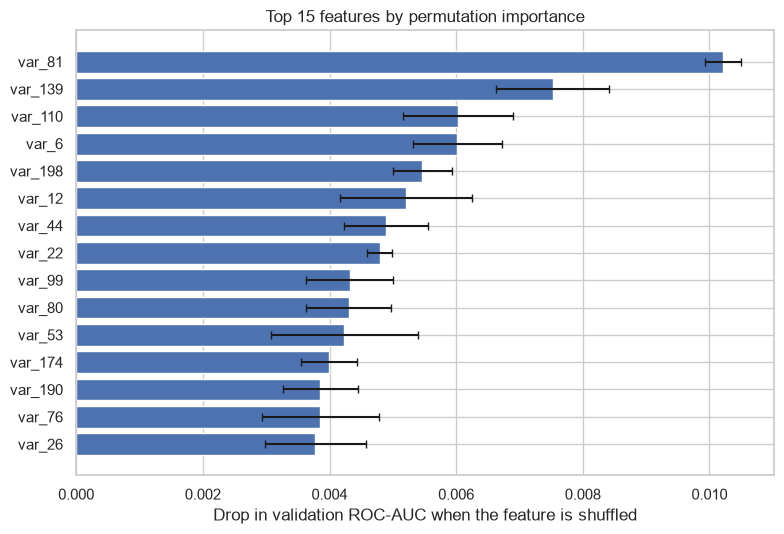

Largest single-feature importance: 0.0102 ROC-AUC. Features with importance above zero: 173 of 200.


In [27]:
# 9.1 Permutation importance on a validation sample (for interpretation only; nothing is chosen from it)
imp_sample = X_val.sample(min(8000, len(X_val)), random_state=RANDOM_STATE)
imp = permutation_importance(final_model, imp_sample, y_val.loc[imp_sample.index], scoring="roc_auc",
                             n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
importance = (pd.DataFrame({"feature": X_val.columns, "importance": imp.importances_mean,
                            "std": imp.importances_std})
              .sort_values("importance", ascending=False).reset_index(drop=True))
top15 = importance.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top15["feature"], top15["importance"], xerr=top15["std"], capsize=3, color=sns.color_palette()[0])
ax.set_xlabel("Drop in validation ROC-AUC when the feature is shuffled")
ax.set_title("Top 15 features by permutation importance")
plt.tight_layout()
plt.show()
print(f"Largest single-feature importance: {importance['importance'].max():.4f} ROC-AUC. "
      f"Features with importance above zero: {(importance['importance'] > 0).sum()} of {len(importance)}.")

In [28]:
# 9.2 Does using fewer features cost accuracy? Rank on the fit set only, test on validation.
uni_auc = X_fit.apply(lambda col: roc_auc_score(y_fit_arr, col))
ranked_features = (uni_auc - 0.5).abs().sort_values(ascending=False).index.tolist()

full_val_auc = roc_auc_score(y_val_arr, val_scores)
rows = [{"features used": len(feature_cols), "validation ROC-AUC": full_val_auc, "change vs all": 0.0}]
for k in [50, 100, 150]:
    if k >= len(feature_cols):
        continue
    cols = ranked_features[:k]
    m = clone(final_model).fit(X_fit[cols], y_fit_arr)
    auc_k = roc_auc_score(y_val_arr, m.predict_proba(X_val[cols])[:, 1])
    rows.append({"features used": k, "validation ROC-AUC": auc_k, "change vs all": auc_k - full_val_auc})
selection = pd.DataFrame(rows).sort_values("features used").reset_index(drop=True)
display(selection.round(4))

# 9.3 PCA: is there redundancy to compress?
pca = PCA().fit(StandardScaler().fit_transform(X_fit))
cum_var = np.cumsum(pca.explained_variance_ratio_)
n_comp_90 = int(np.searchsorted(cum_var, 0.90) + 1)
n_comp_95 = int(np.searchsorted(cum_var, 0.95) + 1)
print(f"PCA: {n_comp_90} components are needed for 90% of the variance and {n_comp_95} for 95% (out of {len(feature_cols)}).")

,features used,validation ROC-AUC,change vs all
0,50,0.8451,-0.0506
1,100,0.8872,-0.0086
2,150,0.8959,0.0001
3,200,0.8958,0.0000


PCA: 179 components are needed for 90% of the variance and 190 for 95% (out of 200).


**Reading the results.**
- *Feature selection:* if the validation ROC-AUC barely changes with fewer features, the model could be simplified; if it drops, the signal is spread across many features and all are kept. The table above decides this.
- *PCA:* components are only useful when features are correlated. With very weak correlation between features (Part 2.7), PCA cannot compress much, so it is not applied. The component counts above confirm this.

## Part 10 · Making predictions directly in the notebook (no pickle file)

The trained model (`final_model`) and the chosen `THRESHOLD` already exist in memory, so predictions need no saving or reloading. `predict_customers` turns any table of the 200 features into probabilities and a decision.

In [29]:
def predict_customers(features, ids=None):
    """Return transaction probability and a yes/no decision for each customer."""
    missing = [c for c in feature_cols if c not in features.columns]
    if missing:
        raise ValueError(f"Missing {len(missing)} feature columns, e.g. {missing[:3]}")
    scores = final_model.predict_proba(features[feature_cols])[:, 1]
    return pd.DataFrame({
        "ID_code": ids if ids is not None else features.index,
        "transaction_probability": scores.round(4),
        "predicted_transaction": (scores >= THRESHOLD).astype(int),
    })


# Held-out customers (their true outcome is known, so we can verify the output)
holdout_predictions = predict_customers(X_test, customer_ids.loc[X_test.index].to_numpy())
holdout_predictions["actual_transaction"] = y_test_arr
assert (holdout_predictions["predicted_transaction"].to_numpy() == test_pred).all()
display(holdout_predictions.head(10))
print(f"Flagged as likely to transact: {holdout_predictions['predicted_transaction'].sum():,} "
      f"of {len(holdout_predictions):,} customers ({holdout_predictions['predicted_transaction'].mean() * 100:.1f}%).")

# Optional: a separate unlabelled file (such as test.csv in the project zip), if it sits next to the notebook
new_path = find_data_file(["test.csv", "test(1).csv"], required=False)
if new_path is not None:
    new_df = pd.read_csv(new_path)
    if set(feature_cols).issubset(new_df.columns) and "target" not in new_df.columns:
        new_predictions = predict_customers(new_df, new_df["ID_code"].to_numpy() if "ID_code" in new_df else None)
        print(f"\nPredictions for {new_path.name}: {len(new_predictions):,} customers, "
              f"{new_predictions['predicted_transaction'].mean() * 100:.1f}% flagged.")
        display(new_predictions.head())
        # new_predictions.to_csv("predictions.csv", index=False)   # uncomment to export
    else:
        print(f"\n{new_path.name} found, but it does not look like an unlabelled feature file; skipped.")
else:
    print("\nNo unlabelled test file found next to the notebook; skipped.")

,ID_code,transaction_probability,predicted_transaction,actual_transaction
0,train_199837,0.0159,0,0
1,train_149409,0.0618,0,0
2,train_43642,0.0053,0,0
3,train_157332,0.0186,0,0
4,train_189470,0.0631,0,0
5,train_40518,0.0667,0,0
6,train_128319,0.0366,0,0
7,train_162220,0.0887,0,0
8,train_119266,0.0153,0,0
9,train_161437,0.0191,0,0


Flagged as likely to transact: 5,737 of 40,000 customers (14.3%).

No unlabelled test file found next to the notebook; skipped.


## Part 11 · Model Comparison Report

In [30]:
# 11.1 All candidate models, same folds, same metrics
report = pd.DataFrame({
    "ROC-AUC (mean ± std)": [f"{r.auc_mean:.4f} ± {r.auc_std:.4f}" for r in cv_summary.itertuples()],
    "Average precision": [f"{r.ap_mean:.3f}" for r in cv_summary.itertuples()],
    "Precision @ top 10%": [f"{r.precision_top10:.3f}" for r in cv_summary.itertuples()],
    "Recall @ top 10%": [f"{r.recall_top10:.3f}" for r in cv_summary.itertuples()],
    "Fit time per fold (s)": [f"{r.fit_seconds:.1f}" for r in cv_summary.itertuples()],
}, index=cv_summary.index)
report["Outcome"] = ["Tuned and selected" if m == tune_name else "" for m in report.index]
display(report)

,ROC-AUC (mean ± std),Average precision,Precision @ top 10%,Recall @ top 10%,Fit time per fold (s),Outcome
Model,,,,,,
Gaussian Naive Bayes,0.8875 ± 0.0034,0.585,0.552,0.549,0.7,
LightGBM,0.8755 ± 0.0045,0.553,0.527,0.525,6.1,Tuned and selected
XGBoost,0.8656 ± 0.0041,0.528,0.510,0.508,16.6,
HistGradientBoosting,0.8616 ± 0.0057,0.511,0.499,0.496,10.3,
Logistic Regression,0.8588 ± 0.0044,0.508,0.496,0.493,1.5,
Extra Trees,0.8500 ± 0.0045,0.478,0.476,0.474,13.1,
Random Forest,0.8154 ± 0.0059,0.414,0.423,0.421,37.0,


In [31]:
# 11.1b Class-balancing strategies (same folds; balancing only inside training folds)
balance_report = pd.DataFrame({
    "ROC-AUC (mean ± std)": [f"{r.auc_mean:.4f} ± {r.auc_std:.4f}" for r in balance_summary.itertuples()],
    "Average precision": [f"{r.ap_mean:.3f}" for r in balance_summary.itertuples()],
    "Precision @ top 10%": [f"{r.precision_top10:.3f}" for r in balance_summary.itertuples()],
    "Recall @ top 10%": [f"{r.recall_top10:.3f}" for r in balance_summary.itertuples()],
    "Rows per model": [f"{r.rows_per_model:,.0f}" for r in balance_summary.itertuples()],
}, index=balance_summary.index)
balance_report["Outcome"] = ["Selected" if i == balance_label else ("Reference only" if i == reference_label else "")
                             for i in balance_report.index]
display(balance_report)

,ROC-AUC (mean ± std),Average precision,Precision @ top 10%,Recall @ top 10%,Rows per model,Outcome
Strategy,,,,,,
No balancing (reference),0.8755 ± 0.0045,0.553,0.527,0.525,"108,800",Reference only
Class weights,0.8756 ± 0.0044,0.555,0.527,0.524,"108,800",
Random oversampling 1:1,0.8743 ± 0.0041,0.550,0.526,0.524,"195,734",
Random undersampling 1:1,0.8749 ± 0.0036,0.550,0.526,0.523,"21,866",
Hybrid (meet in the middle),0.8741 ± 0.0043,0.552,0.529,0.526,"65,420",
Undersampling ensemble (5 bags),0.8822 ± 0.0040,0.574,0.542,0.539,"21,866",Selected


In [33]:
# 11.2 Validation methodology, uncertainty and operational impact of the selected model
val_row = val_table.loc[val_table["threshold"] == THRESHOLD].iloc[0]
brier = brier_score_loss(y_val_arr, val_scores)
summary = pd.DataFrame([
    ["Model comparison", f"{N_SPLITS_CV}-fold CV, fit set ({len(X_fit):,} customers)",
     f"{tune_name}: ROC-AUC {cv_summary.loc[tune_name, 'auc_mean']:.4f} ± {cv_summary.loc[tune_name, 'auc_std']:.4f} (fold std)"],
    ["Class balancing", f"{N_SPLITS_CV}-fold CV, fit set; balanced inside training folds only",
     f"{balance_label}: ROC-AUC {delta_auc:+.4f}, Average precision {delta_ap:+.4f} vs no balancing"],
    ["Tuning", f"3-fold CV, fit set (balanced folds), {N_ITER_SEARCH} random candidates",
     f"Best CV ROC-AUC {search.best_score_:.4f}"],
    ["Overfitting and calibration check", f"Validation set ({len(X_val):,})",
     f"Validation ROC-AUC {overfit.iloc[1, 0]:.4f}; train-validation gap {gap:.4f}; Brier {brier:.4f}"],
    ["Threshold (cost-based)", f"Validation set; value:cost = {VALUE_PER_TRANSACTOR:g}:{COST_PER_CONTACT:g} (assumed)",
     f"Threshold {THRESHOLD:.2f}; validation net value {val_row['net_value_per_1000']:,.0f} per 1,000 customers"],
    ["Final estimate", f"Locked test set ({len(X_test):,}), used once",
     f"ROC-AUC {test_ci.loc['ROC-AUC', 'Test value']:.4f} "
     f"[{test_ci.loc['ROC-AUC', '95% CI low']:.4f}, {test_ci.loc['ROC-AUC', '95% CI high']:.4f}]"],
    ["Operational result (test)", f"Contacting {test_metrics['Customers contacted (%)']:.1f}% of customers",
     f"Precision {test_metrics['Precision']:.3f}, recall {test_metrics['Recall']:.3f}, "
     f"net value {test_metrics['Net value per 1,000 customers']:,.0f} per 1,000 (assumed costs)"],
], columns=["Stage", "Data / method", "Result"])
with pd.option_context("display.max_colwidth", None):
    display(summary)

,Stage,Data / method,Result
0,Model comparison,"5-fold CV, fit set (136,000 customers)",LightGBM: ROC-AUC 0.8755 ± 0.0045 (fold std)
1,Class balancing,"5-fold CV, fit set; balanced inside training folds only","Undersampling ensemble (5 bags): ROC-AUC +0.0068, Average precision +0.0210 vs no balancing"
2,Tuning,"3-fold CV, fit set (balanced folds), 8 random candidates",Best CV ROC-AUC 0.8910
3,Overfitting and calibration check,"Validation set (24,000)",Validation ROC-AUC 0.8958; train-validation gap 0.0231; Brier 0.0632
4,Threshold (cost-based),Validation set; value:cost = 5:1 (assumed),"Threshold 0.16; validation net value 190 per 1,000 customers"
5,Final estimate,"Locked test set (40,000), used once","ROC-AUC 0.8919 [0.8866, 0.8971]"
6,Operational result (test),Contacting 14.3% of customers,"Precision 0.461, recall 0.658, net value 187 per 1,000 (assumed costs)"


## Part 12 · Report on challenges faced

| # | Challenge | Technique used | Why |
|---|---|---|---|
| 1 | **Anonymised features.** No names, so no business interpretation. | Statistical profiling (Part 2) and permutation importance (Part 9). No meaning is assigned to individual features. | We can describe how features behave without inventing a story about what they are. |
| 2 | **Class imbalance (about 10% positives).** A model could score well on accuracy by predicting "no" for everyone, and would see few positive examples. | The training data is balanced (Part 4b) inside each training fold only. Five strategies were compared with a no-balancing reference. Validation and test keep the real class mix. ROC-AUC and Average Precision are used for ranking. | The model learns from both outcomes equally, while evaluation still reflects real use. Balancing is only trusted if cross-validation shows it helps. |
| 2b | **Weaknesses of plain over- and under-sampling.** Duplicated rows can be memorised and dropped rows lose information. | Class weights, a hybrid that meets in the middle, and an ensemble of undersamples were tested as milder options. Resampling happens inside folds, HGB early stopping is switched off, and settings are regularised. | Duplicates never leak into scoring data, and the effect of each weakness is visible in the comparison table. |
| 2c | **Balanced training inflates probabilities.** | A prior correction restores the real-world probability scale (Part 6). | The cost-based threshold and the calibration check need probabilities that mean what they say. |
| 3 | **Weak, spread-out signal.** No single feature is strongly related to the target. | Compared linear, probabilistic and tree-based models, and kept all features after testing a reduced set (Part 9). | The non-linear boosting models can combine many small effects that a linear model cannot. |
| 4 | **Overfitting.** The tuned boosting model fits training data much better than unseen data. | A search space with regularised settings, early stopping and an untouched validation set (Parts 5 and 6). | The honest figure is performance on unseen customers, so selection and judgement use different data. |
| 5 | **Fair model comparison.** Earlier versions gave models different class weights and compared threshold-dependent scores. | Identical CV folds, no class weights, threshold-free metrics and one common operating point (Part 4). | Differences then reflect the model and not the set-up. |
| 6 | **Reusing the test set.** Earlier versions chose models and thresholds with test data. | Three-way split. The test set is locked and used once (Part 8). | The reported test result is an unbiased estimate. |
| 7 | **Choosing a threshold.** F1 treats both kinds of error as equal. | Cost-based threshold with a sensitivity table across value:cost ratios (Part 7). | The decision is tied to the bank's economics and the assumptions are visible and editable. |
| 8 | **Computational cost.** An unrestricted random forest took about 16 minutes for a weak result. | Big-O reasoning (Part 4): depth-limited forests, no KNN or SVM, and a limited random search. | Cost grows with data size, trees and folds, so effort goes to the models that scale. |
| 9 | **Reproducibility and portability.** Earlier versions had hard-coded paths, suppressed warnings and saved pickle files. | Relative path auto-detection, warnings left visible, fixed random seeds and in-notebook prediction (Parts 1 and 10). | Anyone can rerun the notebook and see the same results. |

## Part 13 · Conclusion

In [34]:
top_decile_capture = lift["cumulative_capture_%"].iloc[0]
top_two_deciles = lift["cumulative_capture_%"].iloc[1]
auc_row = test_ci.loc["ROC-AUC"]
others = cv_summary.drop(index=tune_name)
if delta_auc > 0.002:
    balance_effect = 'balancing improved how well customers are ranked.'
elif delta_auc < -0.002:
    balance_effect = 'balancing slightly reduced ranking quality; it was kept because the model learns from both outcomes equally and the probabilities were corrected, but the unbalanced model is a legitimate alternative.'
else:
    balance_effect = 'balancing did not change ranking quality materially. Its value is in giving both outcomes equal weight during learning, with probabilities corrected afterwards.'
if tune_name == best_name:
    runner_up_note = f" The next best, {others.index[0]}, scored {others.iloc[0]['auc_mean']:.4f}."
    rank_claim = "It ranked customers best among all models tested and trains in minutes."
else:
    runner_up_note = ""
    rank_claim = (f"It is the strongest tunable model, but {best_name} scored higher in cross-validation, "
                  f"so {best_name} is worth considering if simplicity matters more than the tree-based option.")

display(Markdown(f"""
### Task 1: what does the data tell us?
- The dataset has {len(df):,} customers and {len(feature_cols)} anonymised numeric features, with no missing values, duplicates or constant features.
- Only **{pct[1]:.1f}%** of customers transact, a class imbalance of {imbalance_ratio:.1f}:1, so accuracy alone is misleading.
- Signal is **weak and spread out**: the strongest single-feature correlation with the target is {target_corr.abs().max():.3f}.
- Features are **nearly uncorrelated** with each other (maximum pairwise correlation {max_pair_corr:.3f}), and PCA needs {n_comp_95} of {len(feature_cols)} components for 95% of the variance. So there is no redundancy to compress and no feature was dropped.

### Task 2: which customers will transact in the future?
- The selected model is **{tune_name}**, tuned on the fit set only. {selection_note}{runner_up_note}
- **Class balancing:** the training data was balanced with *{balance_label}* (inside training folds only). Compared with training on the original data, cross-validated ROC-AUC changed by {delta_auc:+.4f} and Average Precision by {delta_ap:+.4f}, so {balance_effect}
- On the locked test set it reaches **ROC-AUC {auc_row['Test value']:.3f}** (95% CI {auc_row['95% CI low']:.3f} to {auc_row['95% CI high']:.3f}) and Average Precision {test_metrics['Average precision']:.3f}, against a random baseline of {y_test_arr.mean():.3f}.
- Contacting the top-scored 10% of customers reaches **{top_decile_capture:.0f}%** of all transacting customers, and the top 20% reaches **{top_two_deciles:.0f}%** (validation set).
- At the cost-based threshold of {THRESHOLD:.2f}, the bank would contact {test_metrics['Customers contacted (%)']:.1f}% of customers and reach {test_metrics['Recall'] * 100:.0f}% of the transacting ones, with {test_metrics['Precision'] * 100:.0f}% of contacts being genuine transactors.

### Recommendation for production
Use **{tune_name}** with the cost-based threshold, and re-set the threshold with the bank's real contact cost and customer value (Part 7 shows how the best threshold moves with that ratio). {rank_claim} Its probabilities can be checked with the calibration plot in Part 6.

### Limitations and next steps before deployment
- The costs and values in Part 7 are **assumptions**; real figures could change the threshold materially.
- The features are anonymised and the file has no time or location column, so a random split is the only option. Performance on a later period or new customers has **not** been tested and should be checked on future data.
- The test set has now been read, so it is no longer a clean hold-out. A later period or new customers would be the next independent check.
- Monitor the score distribution and the transaction rate after launch, and retrain if they drift.
- Stronger feature engineering (for example, encoding how common each value is within a feature) is a possible next experiment, but was not tested here.
"""))


### Task 1: what does the data tell us?
- The dataset has 200,000 customers and 200 anonymised numeric features, with no missing values, duplicates or constant features.
- Only **10.0%** of customers transact, a class imbalance of 9.0:1, so accuracy alone is misleading.
- Signal is **weak and spread out**: the strongest single-feature correlation with the target is 0.081.
- Features are **nearly uncorrelated** with each other (maximum pairwise correlation 0.010), and PCA needs 190 of 200 components for 95% of the variance. So there is no redundancy to compress and no feature was dropped.

### Task 2: which customers will transact in the future?
- The selected model is **LightGBM**, tuned on the fit set only. Gaussian Naive Bayes ranked first in cross-validation (ROC-AUC 0.8875), but it has no boosting search space here, so LightGBM, the best tunable model (ROC-AUC 0.8755), was taken forward.
- **Class balancing:** the training data was balanced with *Undersampling ensemble (5 bags)* (inside training folds only). Compared with training on the original data, cross-validated ROC-AUC changed by +0.0068 and Average Precision by +0.0210, so balancing improved how well customers are ranked.
- On the locked test set it reaches **ROC-AUC 0.892** (95% CI 0.887 to 0.897) and Average Precision 0.592, against a random baseline of 0.101.
- Contacting the top-scored 10% of customers reaches **56%** of all transacting customers, and the top 20% reaches **76%** (validation set).
- At the cost-based threshold of 0.16, the bank would contact 14.3% of customers and reach 66% of the transacting ones, with 46% of contacts being genuine transactors.

### Recommendation for production
Use **LightGBM** with the cost-based threshold, and re-set the threshold with the bank's real contact cost and customer value (Part 7 shows how the best threshold moves with that ratio). It is the strongest tunable model, but Gaussian Naive Bayes scored higher in cross-validation, so Gaussian Naive Bayes is worth considering if simplicity matters more than the tree-based option. Its probabilities can be checked with the calibration plot in Part 6.

### Limitations and next steps before deployment
- The costs and values in Part 7 are **assumptions**; real figures could change the threshold materially.
- The features are anonymised and the file has no time or location column, so a random split is the only option. Performance on a later period or new customers has **not** been tested and should be checked on future data.
- The test set has now been read, so it is no longer a clean hold-out. A later period or new customers would be the next independent check.
- Monitor the score distribution and the transaction rate after launch, and retrain if they drift.
- Stronger feature engineering (for example, encoding how common each value is within a feature) is a possible next experiment, but was not tested here.
